# **Gradient Boosting: From Residuals to Functional Gradient Descent**

**Gradient boosting** is one of the most effective machine learning methods for structured (tabular) data. Instead of training a single complex model, it builds a strong predictor out of many simple ones, usually shallow decision trees, added one at a time.

The model starts from a trivial guess, such as the mean of the target, and then improves in rounds: at each step, a small tree $h_m(x)$ is fitted to the errors that the current ensemble still makes, and a scaled-down version of that tree is added to the model,

$$F_m(x) = F_{m-1}(x) + \nu\, h_m(x),$$

where $\nu$ is the learning rate.

The method is called **gradient boosting**, because these "errors" are in fact the negative gradient of a loss function with respect to the current predictions, so every new tree performs one step of gradient descent in the space of functions. This idea works with any differentiable loss, which is why the same algorithm handles regression, classification, ranking and more, and why it powers libraries such as **XGBoost** and **LightGBM**.

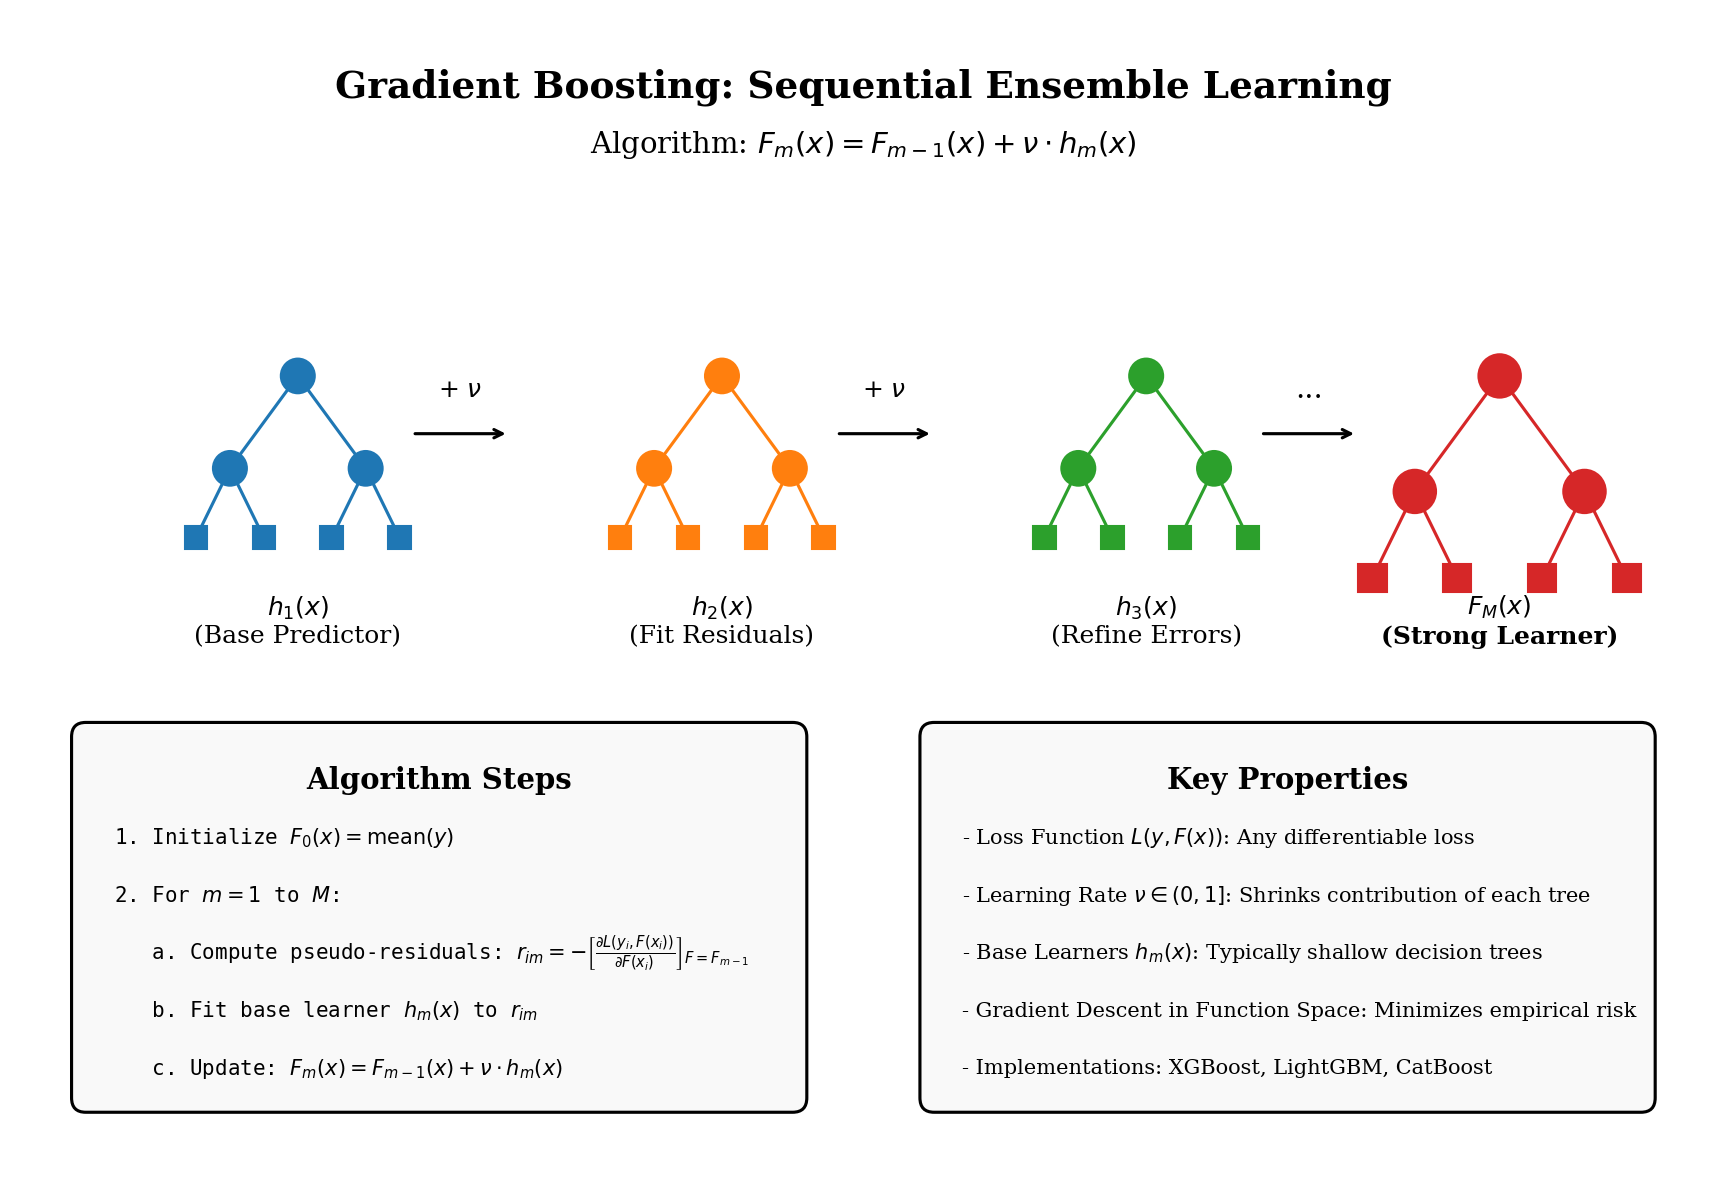

## **Ensembles of weak learners**

A single decision tree is easy to interpret but is either too simple (underfits) or too deep (overfits). **Ensembles** combine many trees:

* **Bagging / Random Forest** - train many *deep* trees **independently** on bootstrap samples, then average. Goal: reduce **variance**.
* **Boosting** - train many *shallow* trees **sequentially**, where each new tree focuses on what the current ensemble still gets wrong. Goal: reduce **bias**.

| | Random Forest | Gradient Boosting |
|---|---|---|
| Training order | parallel (independent trees) | sequential (tree $m$ depends on trees $1..m-1$) |
| Typical tree | deep, low bias, high variance | shallow (depth 3-8), high bias, low variance |
| Combination | average / vote | **sum** of scaled trees |
| Main risk | few; rarely overfits with more trees | **can overfit** if too many trees / learning rate too high |
| Main tuning knobs | `n_estimators`, `max_features` | `learning_rate`, `n_estimators`, `max_depth`, `subsample` |

> **Historical note.** AdaBoost (Freund & Schapire, 1995) boosts by re-weighting misclassified samples. Breiman observed that boosting can be seen as optimization of a cost function; Friedman (2001) turned this into **gradient boosting** - a general recipe that works with *any differentiable loss*.


**Gradient boosting** builds the model **additively**:

$$
F_M(x) \;=\; F_0(x) \;+\; \nu \sum_{m=1}^{M} h_m(x).
$$

1. Start with a very simple model $F_0$ (a constant, e.g. the mean of the target).
2. Compute the errors (**residuals**) of the current model.
3. Fit a small tree $h_m$ **to the errors**.
4. Add a *scaled-down* version of the tree to the model: $F_m = F_{m-1} + \nu\, h_m$.
5. Repeat steps 2-4.

Each tree is a small "correction" of the previous predictions. The learning rate $\nu$ makes every correction deliberately timid, so that many small steps are taken in the right direction instead of a few big ones that overshoot.



## **Example: regression with mixed features**

**Task.** Predict the price of an apartment (in thousand USD) from its area (in m$^2$, numerical) and floor type (categorical: `low` or `high`).

| $i$ | area $x_{i1}$ | floor $x_{i2}$ | price $y_i$ |
|:-:|:-:|:-:|:-:|
| 1 | 20 | low | 80 |
| 2 | 40 | high | 160 |
| 3 | 60 | low | 200 |
| 4 | 80 | high | 280 |

**Settings:** squared-error loss $L(y, F) = \frac{1}{2}(y - F)^2$, trees are *stumps* (one split, two leaves), learning rate $\nu = 0.5$.

### Step 0 — initial prediction

The best constant for squared error is the mean of the target:

$$
F_0 = \frac{80 + 160 + 200 + 280}{4} = 180.
$$

The mean squared error (MSE) of this trivial model is:
$$
\text{MSE}_0 = \frac{1}{4}\left[ (80-180)^2 + (160-180)^2 + (200-180)^2 + (280-180)^2 \right] = \frac{10000 + 400 + 400 + 10000}{4} = 5200.
$$

### Step 1 — first tree (numerical split)

Compute the negative gradient (residuals) $r_{i1} = y_i - F_0$:

| $i$ | area | floor | $y_i$ | $F_0$ | $r_{i1} = y_i - F_0$ |
|:-:|:-:|:-:|:-:|:-:|:-:|
| 1 | 20 | low | 80 | 180 | $-100$ |
| 2 | 40 | high | 160 | 180 | $-20$ |
| 3 | 60 | low | 200 | 180 | $+20$ |
| 4 | 80 | high | 280 | 180 | $+100$ |

We search for the best stump (one split) across **both** features that minimizes the Sum of Squared Errors (SSE) in the leaves.

> **How do we choose the best split? (Understanding SSE)**
> When a tree makes a split, it divides the data into two groups (leaves). For regression, the tree will predict the **mean value** of the residuals in each leaf.
> To decide which split is the best, we calculate the **SSE**. It measures how far the actual residuals are from their leaf's mean. The formula for a single observation is:
> $$ \text{Error}^2 = (\text{actual_residual} - \text{leaf_mean})^2 $$
> We calculate this squared error for every observation and sum them all up. The split with the **lowest total SSE** is the winner, because it means the leaf means represent the data in those groups as accurately as possible.

For a numerical feature with sorted values $\{20, 40, 60, 80\}$, the candidate thresholds are the midpoints between adjacent values: **30, 50, and 70**. For the categorical feature, we test the partition `floor == 'low'`. Let's evaluate all candidates:

**1. Numerical candidates (`area`):**
*   **Threshold $\le 30$:**
    *   Left ($\le 30$): $\{-100\} \rightarrow \text{mean} = -100$.
    *   Right ($> 30$): $\{-20, +20, +100\} \rightarrow \text{mean} = 100/3 \approx +33.3$.
    *   $\text{SSE} = (-100 - (-100))^2 + (-20 - 33.3)^2 + (20 - 33.3)^2 + (100 - 33.3)^2 \approx 0 + 2844 + 177 + 4444 = \mathbf{7467}$.
*   **Threshold $\le 50$:**
    *   Left ($\le 50$): $\{-100, -20\} \rightarrow \text{mean} = -60$.
    *   Right ($> 50$): $\{+20, +100\} \rightarrow \text{mean} = +60$.
    *   $\text{SSE} = (-100 - (-60))^2 + (-20 - (-60))^2 + (20 - 60)^2 + (100 - 60)^2 = 1600 + 1600 + 1600 + 1600 = \mathbf{6400}$.
*   **Threshold $\le 70$:**
    *   Left ($\le 70$): $\{-100, -20, +20\} \rightarrow \text{mean} = -100/3 \approx -33.3$.
    *   Right ($> 70$): $\{+100\} \rightarrow \text{mean} = +100$.
    *   $\text{SSE} = (-100 - (-33.3))^2 + (-20 - (-33.3))^2 + (20 - (-33.3))^2 + (100 - 100)^2 \approx 4444 + 177 + 2844 + 0 = \mathbf{7467}$.

**2. Categorical candidate (`floor`):**
*   **Split `floor == 'low'`:**
    *   Left (`low`): $\{-100, +20\} \rightarrow \text{mean} = -40$.
    *   Right (`high`): $\{-20, +100\} \rightarrow \text{mean} = +40$.
    *   $\text{SSE} = (-100 - (-40))^2 + (20 - (-40))^2 + (-20 - 40)^2 + (100 - 40)^2 = 3600 + 3600 + 3600 + 3600 = \mathbf{14400}$.

Comparing all options, the numerical split **`area <= 50`** yields the lowest SSE (6400) and wins. Our first weak learner is:
$$
h_1(x) = \begin{cases} -60, & \text{if area} \le 50 \\ +60, & \text{if area} > 50 \end{cases}
$$

Update the model with $\nu = 0.5$:
$$
F_1(x) = F_0 + 0.5 \cdot h_1(x) = \begin{cases} 180 + 0.5(-60) = 150, & \text{area} \le 50 \\ 180 + 0.5(+60) = 210, & \text{area} > 50 \end{cases}
$$

New predictions and MSE:
*   $F_1(20, \text{low}) = 150$, $F_1(40, \text{high}) = 150$, $F_1(60, \text{low}) = 210$, $F_1(80, \text{high}) = 210$.
*   $\text{MSE}_1 = \frac{1}{4}[(80-150)^2 + (160-150)^2 + (200-210)^2 + (280-210)^2] = \frac{4900 + 100 + 100 + 4900}{4} = 2500$.

### Step 2 — second tree (categorical split)

Compute new residuals $r_{i2} = y_i - F_1(x_i)$:

| $i$ | area | floor | $y_i$ | $F_1$ | $r_{i2} = y_i - F_1$ |
|:-:|:-:|:-:|:-:|:-:|:-:|
| 1 | 20 | low | 80 | 150 | $-70$ |
| 2 | 40 | high | 160 | 150 | $+10$ |
| 3 | 60 | low | 200 | 210 | $-10$ |
| 4 | 80 | high | 280 | 210 | $+70$ |

Again, we search for the best stump across both features using the exact same exhaustive search and SSE logic.

**1. Numerical candidates (`area`):**
*   **Threshold $\le 30$:** Left $\{-70\} \rightarrow -70$; Right $\{10, -10, 70\} \rightarrow 23.3$. $\text{SSE} \approx 0 + 177 + 1344 + 2177 = \mathbf{3698}$.
*   **Threshold $\le 50$:** Left $\{-70, 10\} \rightarrow -30$; Right $\{-10, 70\} \rightarrow 30$. $\text{SSE} = (-40)^2 + (40)^2 + (-40)^2 + (40)^2 = \mathbf{6400}$.
*   **Threshold $\le 70$:** Left $\{-70, 10, -10\} \rightarrow -23.3$; Right $\{70\} \rightarrow 70$. $\text{SSE} \approx 2177 + 1344 + 177 + 0 = \mathbf{3698}$.

**2. Categorical candidate (`floor`):**
*   **Split `floor == 'low'`:**
    *   Left (`low`): $\{-70, -10\} \rightarrow \text{mean} = -40$.
    *   Right (`high`): $\{+10, +70\} \rightarrow \text{mean} = +40$.
    *   $\text{SSE} = (-70 - (-40))^2 + (-10 - (-40))^2 + (10 - 40)^2 + (70 - 40)^2 = 900 + 900 + 900 + 900 = \mathbf{3600}$.

This time, the categorical split **`floor == 'low'`** wins (3600 < 3698 < 6400)! The algorithm realized that after correcting for area, the remaining errors are best explained by the floor type.

Our second weak learner is:
$$
h_2(x) = \begin{cases} -40, & \text{if floor} = \text{'low'} \\ +40, & \text{if floor} = \text{'high'} \end{cases}
$$

Update the model:
$$
F_2(x) = F_1(x) + 0.5 \cdot h_2(x)
$$
*   $i=1$ (20, low): $150 + 0.5(-40) = 130$
*   $i=2$ (40, high): $150 + 0.5(+40) = 170$
*   $i=3$ (60, low): $210 + 0.5(-40) = 190$
*   $i=4$ (80, high): $210 + 0.5(+40) = 230$

New MSE:
$$
\text{MSE}_2 = \frac{1}{4}[(80-130)^2 + (160-170)^2 + (200-190)^2 + (280-230)^2] = \frac{2500 + 100 + 100 + 2500}{4} = 1300.
$$

### Summary of the run

| Round $m$ | Feature used | Split rule | Leaf values | MSE |
|:-:|:-:|:-:|:-:|:-:|
| 0 | — | (constant) | 180 | 5200.0 |
| 1 | `area` (num) | $\le 50$ | $-60, +60$ | 2500.0 |
| 2 | `floor` (cat) | $=$ `'low'` | $-40, +40$ | 1300.0 |

### Making a prediction for a new apartment

For a new apartment with **area = 70** and **floor = 'low'**:

1.  Start with $F_0 = 180$.
2.  Tree 1 (`area <= 50`? No, $70 > 50$) $\rightarrow$ add $0.5 \cdot (+60) = +30$. Current: 210.
3.  Tree 2 (`floor == 'low'`? Yes) $\rightarrow$ add $0.5 \cdot (-40) = -20$. Current: 190.

$$
\hat y = 180 + 30 - 20 = 190 \text{ thousand USD}.
$$

>  You can reproduce these exact numbers in Python:
> ```python
> from sklearn.ensemble import GradientBoostingRegressor
> import pandas as pd
>
> df = pd.DataFrame({'area': [20, 40, 60, 80], 'floor': ['low', 'high', 'low', 'high']})
> # One-hot encode for sklearn
> df_enc = pd.get_dummies(df, columns=['floor'], drop_first=True)
> y = [80, 160, 200, 280]
>
> model = GradientBoostingRegressor(n_estimators=2, learning_rate=0.5, max_depth=1)
> model.fit(df_enc, y)
> print(model.predict(df_enc)) # Output: [130. 170. 190. 230.]
> ```

**Key observation.** Gradient boosting naturally handles mixed data types. At each step, it evaluates all possible splits (numerical thresholds and categorical partitions) and greedily picks the one that reduces the loss (SSE) the most. Tree 1 captured the broad trend by area, and Tree 2 specialized in correcting the systematic bias left on different floors.

## **Why is it called gradient boosting?**

Until now, we have treated boosting as a simple recipe: "compute errors, fit a tree to them, add the tree." But why does this work? And why can we use *any* loss function, not just squared error? The answer lies in viewing boosting as an optimization problem in an infinite-dimensional space.

### **Boosting as Optimization in Function Space**

Our goal is to build a prediction function $F(x)$ that minimizes the total loss on the training data:

$$
\mathcal{R}(F) = \sum_{i=1}^{n} L\big(y_i,\, F(x_i)\big).
$$

Here, $y_i$ is the true target, and $F(x_i)$ is the current prediction.


#### 1. How should we improve the predictions?

Suppose we already have a model $F_{m-1}(x)$ from the previous step. Its predictions are not perfect, so we want to improve them.

To determine exactly how each prediction should change, we calculate the derivative of the loss with respect to the current prediction:

$$
g_{im} = \left. \frac{\partial L(y_i, F(x_i))}{\partial F(x_i)} \right|_{F = F_{m-1}}
$$

The derivative tells us the direction in which the loss grows:
*   If $g_{im} > 0$, increasing the prediction *increases* the loss. We should decrease the prediction.
*   If $g_{im} < 0$, increasing the prediction *decreases* the loss. We should increase the prediction.

Therefore, to reduce the loss, we must move in the opposite direction of the gradient. We define this desired correction as the **pseudo-residual** (the negative gradient):

$$
r_{im} = -\, g_{im}
$$

> **Example: Squared-Error Loss**
> For the standard squared-error loss $L(y_i, F(x_i)) = \frac{1}{2}(y_i - F(x_i))^2$, the derivative is:
> $$ \frac{\partial L}{\partial F} = -(y_i - F(x_i)) $$
> Taking the negative gives us the pseudo-residual:
> $$ r_{im} = y_i - F_{m-1}(x_i) $$
> In this familiar case, the pseudo-residual is simply the ordinary difference between the true value and the current prediction.


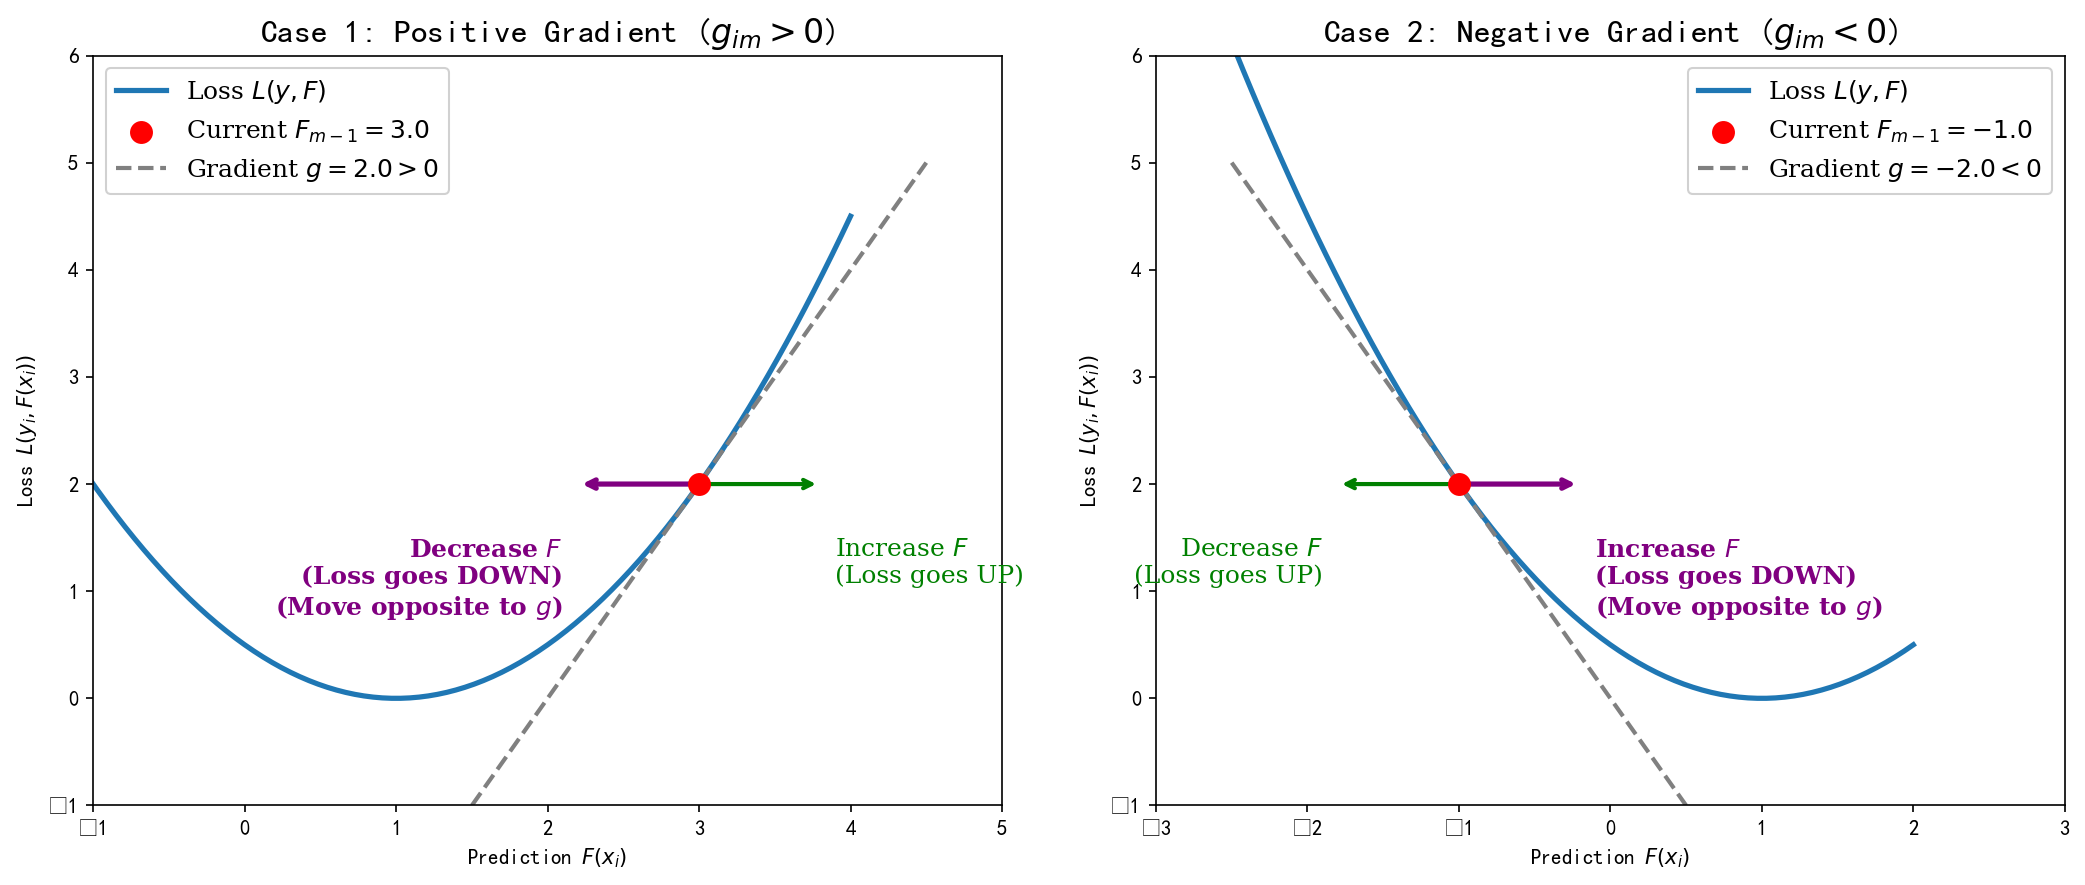

>  **Visualizing the Gradient: Why do we move in the opposite direction?**
>
> Imagine the loss function $L(y, F)$ as a U-shaped valley. Our goal is to reach the bottom (minimum loss). We are currently standing at our prediction $F_{m-1}$. The derivative $g_{im}$ tells us the **slope of the hill** at our current position:
>
> *   **Case 1: Positive Gradient ($g_{im} > 0$)**
>     We are on the right side of the valley. The slope goes UP as we move right. If we increase our prediction $F$, we climb higher (loss increases). To go down, we must move left (decrease $F$). We move *opposite* to the positive gradient.
>     
> *   **Case 2: Negative Gradient ($g_{im} < 0$)**
>     We are on the left side of the valley. The slope goes DOWN as we move right. If we decrease our prediction $F$, we climb higher backwards (loss increases). To go down, we must move right (increase $F$). We move *opposite* to the negative gradient.
>
> In both cases, to reduce the loss, we must take a step in the direction of the **negative gradient** ($-g_{im}$). This is exactly why we define our target correction (the pseudo-residual) as $r_{im} = -g_{im}$.

#### 2. Why can't we correct the predictions directly?

Mathematically, we could update each training prediction directly using its pseudo-residual and a learning rate $\nu$:

$$
F_m(x_i) \approx F_{m-1}(x_i) + \nu \cdot r_{im}
$$

**But there is a fundamental problem:** these corrections $r_{im}$ are calculated *only for the observed training examples*.

How do we determine the appropriate correction for a new, unseen example $x_{\text{new}}$? We don't know its true label $y_{\text{new}}$, so we cannot compute its residual. We need a rule that generalizes beyond the training data.



#### 3. The decision tree learns the correction rule

Instead of applying the corrections directly, we **train a decision tree** to predict them!

We use the input features $x_i$ as predictors and the pseudo-residuals $r_{im}$ as the target values:

$$
\text{Train tree on: } \big\{(x_i, r_{im})\big\}_{i=1}^n
$$

By doing this, the tree learns a generalized rule for how the desired correction depends on the features.
*   *For example, if the current model systematically underestimates the prices of large houses, the residuals for large houses will be positive. The tree will learn a split like `area > 100` and assign a positive correction to that leaf.*

Let $h_m(x)$ denote the correction predicted by this new tree. We update our model for **any** input $x$ (even unseen ones) as follows:

$$
F_m(x) = F_{m-1}(x) + \nu \cdot h_m(x)
$$

Where:
*   $F_{m-1}(x)$ is the current prediction.
*   $h_m(x)$ is the generalized correction predicted by the new tree.
*   $\nu \in (0, 1]$ is the learning rate (shrinkage), which controls how much of the correction we apply at once to prevent overfitting.


#### 4. Why is this called functional gradient descent?

In **ordinary gradient descent** (like in linear regression or neural networks), we adjust a finite set of *parameters* (e.g., weights $\theta$):
$\theta \leftarrow \theta - \nu \nabla_\theta \mathcal{R}$.

In **gradient boosting**, we don't optimize parameters. We optimize the *function itself* in an infinite-dimensional function space. Each new tree $h_m(x)$ acts as a step in the direction of the negative gradient of the loss function.

After $M$ boosting rounds, our final model is an additive ensemble of all these small gradient steps:

$$
F_M(x) = F_0(x) + \nu \sum_{m=1}^{M} h_m(x).
$$

**The gradient tells us *what* corrections are needed. The tree learns *how* to generalize those corrections to the entire feature space.**

### **(Optional!) The general algorithm (Friedman, 2001)**

With this theory in mind, here is the formal algorithm proposed by Jerome Friedman. Notice that it elegantly separates finding the *structure* of the tree from finding the optimal *values* in its leaves.

**Input:** Training data $\{(x_i,y_i)\}_{i=1}^n$, differentiable loss function $L(y,F)$, number of rounds $M$, learning rate $\nu$, maximum tree size (leaves).

**1. Initialize** the model with the best constant prediction:
$$
F_0(x)=\arg\min_{\gamma}\sum_{i=1}^{n}L(y_i,\gamma).
$$

**2. For** $m=1$ **to** $M$:
*   **(a) Compute pseudo-residuals** (the negative gradient for every observation):
$$
r_{im} =
-\left.
\frac{\partial L(y_i,F(x_i))}{\partial F(x_i)}
\right|_{F=F_{m-1}},
\quad i=1,\ldots,n.
$$
*   **(b) Fit a base learner (regression tree)** to the targets $\{(x_i,r_{im})\}_{i=1}^n$ using standard squared-error splits. This partitions the feature space into $J_m$ disjoint regions (leaves): $R_{1m}, R_{2m}, \dots, R_{J_m}$.
*   **(c) Re-optimize leaf values.** For every leaf $j$, find the optimal output value $\gamma_{jm}$ that minimizes the *actual* loss $L$ (not just the squared error of the residuals):
$$
\gamma_{jm}
=
\arg\min_{\gamma}
\sum_{i:\,x_i\in R_{jm}}
L\left(y_i,F_{m-1}(x_i)+\gamma\right)
$$
*   **(d) Update the model** by adding the new tree, scaled by the learning rate:
    $$ F_m(x)=F_{m-1}(x)+\nu\sum_{j=1}^{J_m}\gamma_{jm}\,\mathbb{I}\big(x\in R_{jm}\big). $$

**Output:** The final strong learner $F_M(x)$.

> **Crucial Insight: Two stages per round**
> *   In **step (b)**, we use standard MSE to find *where to split* (the tree structure). Decision trees are great at minimizing MSE, so we use them to approximate the gradient.
> *   In **step (c)**, once the regions $R_{jm}$ are fixed, we calculate the exact optimal step size $\gamma_{jm}$ for the *true* loss function $L$. This makes the algorithm mathematically rigorous even for complex losses like LogLoss or Huber.

### **(Optional!) Other loss functions**



If we want to solve a different task (e.g., robust regression or classification), we **do not change the algorithm**. We only change three components: the pseudo-residual formula, the initial value, and the leaf value calculation.

Here is the "cheat sheet" for the most common loss functions:

| Task / Loss $L(y,F)$ | Pseudo-residual $r_{im}$ (Step a) | Initial $F_0$ (Step 1) | Optimal Leaf Value $\gamma_{jm}$ (Step c) |
| :--- | :--- | :--- | :--- |
| **Squared Error (MSE)**<br>$\frac{1}{2}(y-F)^2$ | $y_i - F(x_i)$ | Mean of $y$ | Mean of $r_i$ in leaf |
| **Absolute Error (MAE)**<br>$\lvert y-F\rvert$ | $\operatorname{sign}\big(y_i - F(x_i)\big)$ | Median of $y$ | Median of $r_i$ in leaf |
| **Huber Loss**<br>*(quadratic near 0, linear in tails)* | Residual clipped to $[-\delta, \delta]$ | Median of $y$ | Robust blend (weighted median) |
| **Log-Loss (Binary Class.)**<br>$- [y \log(p) + (1-y)\log(1-p)]$ | $y_i - p_i$ <br>*(where $p_i = \sigma(F(x_i))$)* | $\log\left(\frac{\bar y}{1-\bar y}\right)$ | $\dfrac{\sum_{x_i \in R_{jm}} r_i}{\sum_{x_i \in R_{jm}} p_i(1-p_i)}$ |


To understand why we need alternatives to Squared Error, imagine we have an outlier: a true value of $y = 1,000,000$ while our model currently predicts $F(x) = 0$.

*   **The MSE problem:** The residual is $1,000,000$. Because MSE squares this error, the gradient is massive. The next tree will bend entirely towards this single outlier, destroying the predictions for all normal data points.
*   **The MAE solution:** The pseudo-residual is just the sign: $\operatorname{sign}(1,000,000 - 0) = \mathbf{+1}$. The outlier contributes the exact same "push" as an observation that is off by just $1$ unit. This makes MAE **highly robust to outliers**. However, MAE has a flaw: its derivative is discontinuous at zero (it jumps from -1 to +1), which can make optimization unstable and slow when errors are already small.

**Huber Loss**

Huber Loss is a mathematical compromise between MSE and MAE. It behaves like MSE when the error is small (smooth optimization), but switches to MAE when the error is large (outlier protection).

It is defined using a threshold parameter $\delta$ (delta):

$$
L_\delta(y, F) = \begin{cases}
\frac{1}{2}(y - F)^2, & \text{if } |y - F| \le \delta \quad \text{(quadratic zone)} \\[6pt]
\delta \cdot |y - F| - \frac{1}{2}\delta^2, & \text{if } |y - F| > \delta \quad \text{(linear zone)}
\end{cases}
$$

**How it affects Gradient Boosting:**
When we take the negative gradient of the Huber loss to get the pseudo-residuals, we get a **clipped residual**:

$$
r_{im} = \begin{cases}
y_i - F_{m-1}(x_i), & \text{if } |y_i - F_{m-1}(x_i)| \le \delta \\[4pt]
\delta \cdot \operatorname{sign}\big(y_i - F_{m-1}(x_i)\big), & \text{if } |y_i - F_{m-1}(x_i)| > \delta
\end{cases}
$$

Let's go back to our outlier ($y = 1,000,000$, prediction $= 0$) and assume we set $\delta = 10$:
1.  The raw error is $1,000,000$.
2.  Since $1,000,000 > 10$, we are in the linear zone.
3.  The pseudo-residual becomes $\delta \cdot \operatorname{sign}(1,000,000) = 10 \cdot (+1) = \mathbf{10}$.

Instead of exploding to $1,000,000$ (like MSE) or shrinking all the way to $1$ (like MAE), the gradient is safely capped at $10$.


In practice, libraries like XGBoost and LightGBM allow you to simply set `objective='huber'` (and optionally specify `huber_delta`). The algorithm automatically handles the clipping of pseudo-residuals and adjusts the leaf calculations, giving you a robust model without any manual outlier cleaning.

## **Gradient boosting for classification**

In regression, our model $F(x)$ outputted a direct numerical value (like price). In classification, we want to output probabilities. However, decision trees are additive: if we simply add up tree outputs, the result can easily fall outside the valid probability range of $[0, 1]$.


### Setup

Instead of predicting the probability $p(x)$ directly, our ensemble $F(x)$ will predict the **log-odds** (logit). To get the actual probability, we pass $F(x)$ through the sigmoid function $\sigma$:

$$
p(x)=\sigma\big(F(x)\big)=\frac{1}{1+e^{-F(x)}},
\qquad \text{and conversely} \qquad
F(x)=\log\frac{p(x)}{1-p(x)} .
$$

Because $F(x)$ can be any number from $-\infty$ to $+\infty$, we can safely add as many trees to it as we want. We only convert to probability at the very end when making a prediction.

For binary classification ($y \in \{0, 1\}$), the standard loss function is the negative log-likelihood (**Log-Loss** or Cross-Entropy). If we substitute $p = \sigma(F)$ into the standard log-loss formula, we get the loss expressed directly in terms of our model's raw output $F$:

$$
L(y,F) = -y\log p - (1-y)\log(1-p) = \log\big(1+e^{F}\big) - yF .
$$




### Example 2: binary classification with mixed features

In regression with Squared Error, the optimal leaf value was simply the **mean of the residuals**.
In classification with Log-Loss, the intuition is exactly the same. The optimal leaf value $\gamma$ is a **weighted mean of the residuals**:

$$
\gamma = \frac{\text{Sum of residuals in leaf}}{\text{Sum of "confidence weights" in leaf}} = \frac{\sum r_i}{\sum p_i(1-p_i)}
$$

> **What is this weight $w_i = p_i(1-p_i)$?**
> It measures how "uncertain" the current prediction is.
> *   If $p = 0.5$ (maximum uncertainty), the weight is $0.5 \times 0.5 = \mathbf{0.25}$ (maximum). The model says: *"I am confused, I need a large correction!"*
> *   If $p = 0.9$ (high confidence), the weight is $0.9 \times 0.1 = \mathbf{0.09}$ (small). The model says: *"I am already confident, apply only a small correction so I don't overshoot."*
>
> So, instead of a simple average, we take an average where uncertain predictions get larger.

**Task.** Predict whether a student passes (`1`) or fails (`0`) based on study hours and lecture attendance.

| $i$ | hours $x_{i1}$ | attendance $x_{i2}$ | pass $y_i$ |
|:-:|:-:|:-:|:-:|
| 1 | 1 | low | 0 |
| 2 | 2 | high | 1 |
| 3 | 3 | low | 0 |
| 4 | 7 | low | 1 |
| 5 | 8 | high | 1 |
| 6 | 9 | low | 1 |

**Settings:** Log-loss, stumps (max depth 1), learning rate $\nu = 0.5$.

#### Step 0 — Initialization
4 out of 6 students passed. Baseline probability $\bar{y} = 4/6 \approx 0.667$.
We convert this to log-odds to initialize our model $F_0$:
$$
F_0 = \log\frac{0.667}{1 - 0.667} = \log(2) \approx \mathbf{0.693}.
$$
Currently, the model predicts $p_i = \sigma(0.693) = \mathbf{0.667}$ for everyone.

#### Step 1 — First Tree (Numerical Split)
**1. Calculate pseudo-residuals ($r_i = y_i - p_i$):**
*   For failures ($y=0$, students 1, 3): $r = 0 - 0.667 = \mathbf{-0.667}$
*   For passes ($y=1$, students 2, 4, 5, 6): $r = 1 - 0.667 = \mathbf{+0.333}$

**2. Find the best split:**
We test all midpoints for `hours` (1.5, 2.5, 5.0, 7.5, 8.5) and the categorical split for `attendance`.
The algorithm finds that splitting by **hours $\le 5$** minimizes the loss the most.
*   **Left leaf ($\le 5$):** Students {1, 2, 3}. Residuals: $\{-0.667, +0.333, -0.667\}$.
*   **Right leaf ($> 5$):** Students {4, 5, 6}. Residuals: $\{+0.333, +0.333, +0.333\}$.

**3. Calculate optimal leaf values ($\gamma$) using the weighted average:**
Since everyone has $p_i = 0.667$, all weights are identical: $w_i = 0.667(1 - 0.667) \approx \mathbf{0.222}$.
*   **Left leaf:**
    $$ \gamma_L = \dfrac{-0.667 + 0.333 - 0.667}{0.222 + 0.222 + 0.222} = \dfrac{-1.001}{0.666} \approx \mathbf{-1.50} $$
*   **Right leaf:**
    $$ \gamma_R = \frac{0.333 + 0.333 + 0.333}{0.222 + 0.222 + 0.222} = \dfrac{0.999}{0.666} \approx \mathbf{+1.50} $$

**4. Update the model ($F_1 = F_0 + \nu \cdot \gamma$) and get new probabilities:**
*   **Students 1-3 (Left):**
    *   $F_1 = 0.693 + 0.5(-1.50) = \mathbf{-0.057}$.
    *   $p_1 = \sigma(-0.057) \approx \mathbf{0.486}$.
*   **Students 4-6 (Right):**
    *   $F_1 = 0.693 + 0.5(+1.50) = \mathbf{1.443}$.
    *   $p_1 = \sigma(1.443) \approx \mathbf{0.809}$.

*The model adapted: probability dropped below 50% for low study hours, and rose to 81% for high study hours.*

#### Step 2 — Second Tree (Categorical Split)
**1. New pseudo-residuals ($r_i = y_i - p_{i1}$):**
*   Student 1 ($y=0, p=0.486$): $\mathbf{-0.486}$
*   Student 2 ($y=1, p=0.486$): $\mathbf{+0.514}$
*   Student 3 ($y=0, p=0.486$): $\mathbf{-0.486}$
*   Students 4, 5, 6 ($y=1, p=0.809$): $1 - 0.809 = \mathbf{+0.191}$

**2. Find the best split:**
Now the weights $w_i = p_i(1-p_i)$ are no longer identical!
*   For students 1, 2, 3 ($p \approx 0.486$): $w = 0.486(0.514) \approx \mathbf{0.250}$. *(High weight: model is uncertain)*
*   For students 4, 5, 6 ($p \approx 0.809$): $w = 0.809(0.191) \approx \mathbf{0.155}$. *(Lower weight: model is confident)*

The algorithm tests all splits again. This time, the numerical splits on `hours` yield lower gains because the remaining errors are perfectly explained by `attendance`. The best split is **attendance == 'low'**.
*   **Left leaf (`low`):** Students {1, 3, 4, 6}. Residuals: $\{-0.486, -0.486, +0.191, +0.191\}$.
*   **Right leaf (`high`):** Students {2, 5}. Residuals: $\{+0.514, +0.191\}$.

**3. Calculate leaf values ($\gamma$):**

For the **Left leaf (`low`)** (Students 1, 3, 4, 6):
*   Sum of residuals: $-0.486 - 0.486 + 0.191 + 0.191 = -0.590$
*   Sum of weights: $0.250 + 0.250 + 0.155 + 0.155 = 0.810$

$$ \gamma_L = \frac{-0.590}{0.810} \approx -0.729 $$

For the **Right leaf (`high`)** (Students 2, 5):
*   Sum of residuals: $0.514 + 0.191 = +0.705$
*   Sum of weights: $0.250 + 0.155 = 0.405$

$$ \gamma_R = \frac{0.705}{0.405} \approx +1.744 $$

**4. Update the model ($F_2 = F_1 + 0.5 \cdot \gamma$):**
*   **Students 1, 3, 4, 6 (`low`):**
    *   $F_2 (\text{S1, S3}) = -0.057 + 0.5(-0.729) = \mathbf{-0.422} \rightarrow p_2 = \sigma(-0.422) \approx \mathbf{0.396}$.
    *   $F_2 (\text{S4, S6}) = 1.443 + 0.5(-0.729) = \mathbf{1.079} \rightarrow p_2 = \sigma(1.079) \approx \mathbf{0.746}$.
*   **Students 2, 5 (`high`):**
    *   $F_2 (\text{S2}) = -0.057 + 0.5(+1.744) = \mathbf{0.815} \rightarrow p_2 = \sigma(0.815) \approx \mathbf{0.693}$.
    *   $F_2 (\text{S5}) = 1.443 + 0.5(+1.744) = \mathbf{2.315} \rightarrow p_2 = \sigma(2.315) \approx \mathbf{0.910}$.


| Round | Feature used | Split rule | Probabilities $(p_1, p_2, p_3, p_4, p_5, p_6)$ |
|:-:|:-:|:-:|:-:|
| 0 | — | (constant) | (0.667, 0.667, 0.667, 0.667, 0.667, 0.667) |
| 1 | `hours` (num) | $\le 5$ | (0.486, 0.486, 0.486, 0.809, 0.809, 0.809) |
| 2 | `att` (cat) | $=$ `'low'` | (0.396, 0.693, 0.396, 0.746, 0.910, 0.746) |

### Making a prediction for a new student

Suppose we have a new student who studied for **6 hours** and had **'high'** attendance. How do we predict their probability of passing?

> **Rule:** Never add tree outputs directly to probabilities!
> Trees output corrections on the **log-odds scale ($F$)**. You must sum everything in log-odds first, and only *then* apply the sigmoid function to get a valid probability.

**Step-by-step prediction:**

1.  **Start with the base model:** $F_0 = 0.693$.
2.  **Apply Tree 1 (`hours <= 5`):**
    The student studied 6 hours, so $6 > 5$. They fall into the **Right leaf**.
    Add the right leaf's correction: $+1.50$.
    Current $F = 0.693 + 1.50 = 2.193$.
3.  **Apply Tree 2 (`attendance == 'low'`):**
    The student has `'high'` attendance, so they fall into the **Right leaf**.
    Add the right leaf's correction: $+1.744$.
    Final $F_{\text{new}} = 2.193 + 1.744 = \mathbf{3.937}$.
4.  **Convert to probability:**
    $$ p_{\text{new}} = \sigma(3.937) = \frac{1}{1 + e^{-3.937}} \approx \mathbf{0.981} $$

The model predicts a **98.1%** chance of passing for this student.

### Multiclass classification (brief overview)

What if we have $K > 2$ classes (e.g., predicting digits 0-9)?

The logic extends naturally using the **Softmax** function instead of the Sigmoid. The model maintains $K$ separate additive ensembles (score functions) $F_1(x), \dots, F_K(x)$—one for each class. The probability of class $k$ is:

$$
p_k(x)=\frac{e^{F_k(x)}}{\sum_{l=1}^{K}e^{F_l(x)}} .
$$

In every boosting round, we build **$K$ separate trees** (one per class).
*   The pseudo-residual for class $k$ is simply the indicator minus the predicted probability: $r_{ik} = \mathbb{I}(y_i=k) - p_k(x_i)$.
*   The leaf values are calculated using a generalized version of the Newton step we derived above.

This means that for a 10-class problem, 10 trees are added at every single iteration! This is why multiclass gradient boosting can be computationally expensive, and why libraries like LightGBM and XGBoost use advanced histogram-based optimizations to speed up the search for splits across all these trees simultaneously.

## **Resources**

1. StatQuest with Josh Starmer, Gradient Boost playlist (Parts 1-4): regression main ideas, regression details, classification main ideas, classification details.

2. J. H. Friedman (2001). Greedy Function Approximation: A Gradient Boosting Machine. Annals of Statistics 29(5). The original paper.

3. J. H. Friedman (2002). Stochastic Gradient Boosting. Computational Statistics & Data Analysis 38(4).

4. T. Hastie, R. Tibshirani, J. Friedman. The Elements of Statistical Learning, 2nd ed., Chapter 10 (Boosting and Additive Trees).

5. T. Chen, C. Guestrin (2016). XGBoost: A Scalable Tree Boosting System. KDD.
G. Ke et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. NeurIPS.

6. scikit-learn user guide, section Ensemble methods - Gradient-boosted trees.